# Foreign economic assistance scenario analysis

This walkthrough reproduces an AECM exercise with `fsdm.py` and `plot_net_change.py`. Run the snippets in order in one IPython session from the project directory. The Excel loader requires `openpyxl`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from io import BytesIO
from IPython.display import Image, display
from dataclasses import replace
import fsdm

## 1. Identify the intervention concept

In [2]:
nodes, signs = fsdm.load_aecm("AECM 2.0 Model.xlsx")
print(nodes.loc[nodes["name"].str.contains(
    "foreign economic assistance", case=False, na=False
), ["node_id", "name"]])

              node_id                         name
25  EconAssistForeign  Foreign economic assistance


In [4]:
anchor = "EconAssistForeign"

## 2. Inspect incoming and outgoing relationships

In [5]:
print(signs.loc[anchor].loc[lambda row: row.ne(0)])
print(signs[anchor].loc[lambda col: col.ne(0)])

target
CorruptGrand        1
DisasterPrep        1
EconGrowDevel       1
EconRelyForeign     1
GovInstStrength     1
GovServices         1
HumanCrisis        -1
InfrastrucInvest    1
NonGovServices      1
TechTransfer        1
Name: EconAssistForeign, dtype: int64
source
CorruptGrand   -1
GovServices    -1
HumanCrisis     1
Name: EconAssistForeign, dtype: int64


Assistance has positive outgoing links to political corruption and state capture, disaster preparation, economic growth and development, reliance on foreign suppliers, strength of governing institutions, government provision of services, investment in infrastructure, non-government provision of services, and technology transfer. Its outgoing link to humanitarian crisis is negative. Corruption and government services feed back negatively into assistance. Humanitarian crisis feeds back positively.

## 3. Build the incident-link model

In [6]:
model = fsdm.build_aecm_model(
    signs * 0.05, nodes=nodes, anchors=[anchor], selection="incident"
)
print(len(model.concepts), model.weights.ne(0).sum().sum())

11 13


The model has 11 concepts and 13 directed links. It keeps links that touch the anchor. Every link uses the workbook sign and an illustrative magnitude of 0.05.

## 4. Define the control and increased-aid scenarios

In [20]:
baseline = dict.fromkeys(model.concepts.index, 0.5)
targets = {anchor: 0.60}
control = fsdm.build_fsdm_scenario(model, baseline, increments=10)
increased_aid = fsdm.build_fsdm_scenario(model, baseline, targets=targets, increments=10)


The control has no intervention. The aid scenario uses the same normalized baselines and moves assistance toward 0.60. Feedback can move the final value away from the target.

## 5. Run both scenarios and check convergence

In [30]:
control_trajectory, control_diagnostics, control_summary = fsdm.run_fsdm_scenario(control)
aid_trajectory, aid_diagnostics, aid_summary = fsdm.run_fsdm_scenario(increased_aid)
assert control_diagnostics["converged"].all() and aid_diagnostics["converged"].all()
control_final = control_summary.set_index("node_id")["final_value"]
aid_final = aid_summary.set_index("node_id")["final_value"]

In [33]:
control_final

node_id
CorruptGrand         0.5
DisasterPrep         0.5
EconAssistForeign    0.5
EconGrowDevel        0.5
EconRelyForeign      0.5
GovInstStrength      0.5
GovServices          0.5
HumanCrisis          0.5
InfrastrucInvest     0.5
NonGovServices       0.5
TechTransfer         0.5
Name: final_value, dtype: float64

In [34]:
aid_final

node_id
EconAssistForeign    0.599878
HumanCrisis          0.494510
CorruptGrand         0.505490
DisasterPrep         0.505490
EconGrowDevel        0.505490
EconRelyForeign      0.505490
GovInstStrength      0.505490
GovServices          0.505490
InfrastrucInvest     0.505490
NonGovServices       0.505490
TechTransfer         0.505490
Name: final_value, dtype: float64

Both runs converged at all 10 increments. The control remained at baseline. The default per-increment relative change tolerance is 0.01%.aid_final

## 6. Compare final values


In [35]:
comparison = pd.DataFrame({"Control": control_final, "Increased aid": aid_final})
comparison["difference"] = comparison["Increased aid"] - comparison["Control"]
comparison = comparison.sort_values("difference", key=lambda x: x.abs(), ascending=False)
print(comparison.to_string(float_format="{:.6f}".format))

                   Control  Increased aid  difference
node_id                                              
EconAssistForeign 0.500000       0.599878    0.099878
HumanCrisis       0.500000       0.494510   -0.005490
CorruptGrand      0.500000       0.505490    0.005490
DisasterPrep      0.500000       0.505490    0.005490
EconGrowDevel     0.500000       0.505490    0.005490
EconRelyForeign   0.500000       0.505490    0.005490
GovInstStrength   0.500000       0.505490    0.005490
GovServices       0.500000       0.505490    0.005490
InfrastrucInvest  0.500000       0.505490    0.005490
NonGovServices    0.500000       0.505490    0.005490
TechTransfer      0.500000       0.505490    0.005490


Assistance ended at 0.599878. Humanitarian crisis changed by −0.005490 and the other nine related concepts changed by +0.005490 at displayed precision.

## 7. Interpret the results
Interpret direction separately from desirability. Growth and services increased, alongside corruption and reliance on foreign suppliers. An overall welfare judgment requires priorities and tradeoffs. The crisis change represents −0.549 percentage points on the normalized scale. Estimating avoided crisis incidents would require a calibrated mapping to observed events.

## 8. Plot net change

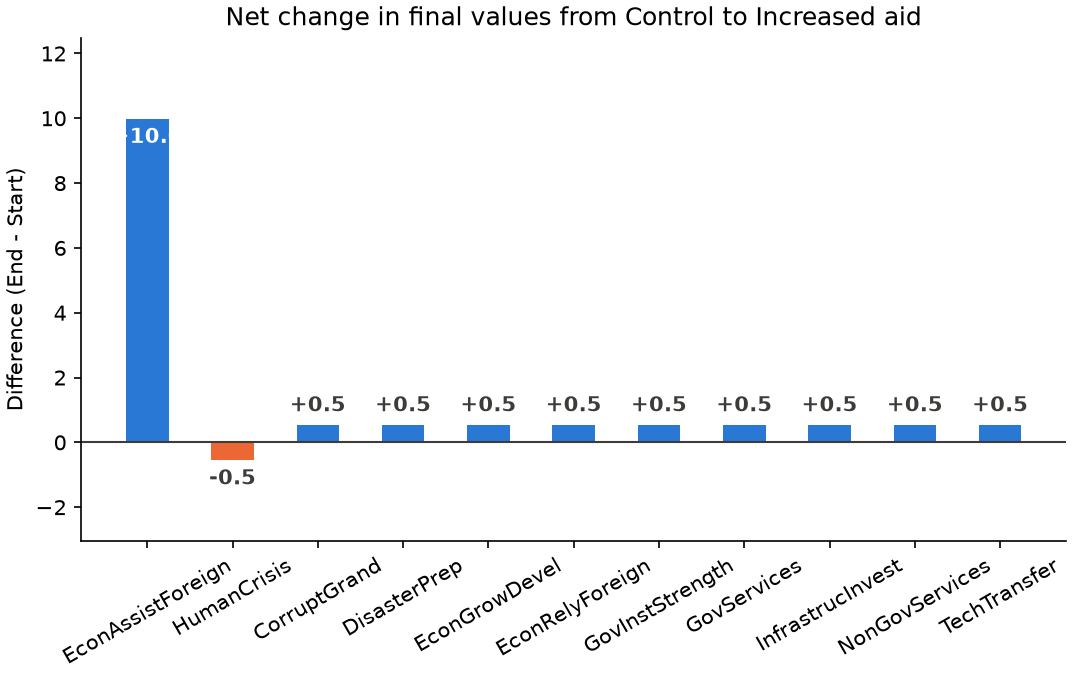

In [58]:
values = comparison[["Control", "Increased aid"]] * 100
matrix = np.asarray(values, dtype=float)
labels = [str(label) for label in values.index]
row_count, column_count = matrix.shape
first, last = values.columns[0], values.columns[-1]
differences = matrix[:, -1] - matrix[:, 0]
fig = Figure(figsize=(max(7, row_count * 0.65), 4.5), layout="constrained")
FigureCanvasAgg(fig)
ax = fig.subplots()
positions = np.arange(row_count)
colors = ["#2a78d6" if change >= 0 else "#eb6834" for change in differences]
bars = ax.bar(positions, differences, color=colors, width=0.5)
dark = "#3d3c39"
ax.axhline(0, color=dark, linewidth=1)
span = np.max(np.abs(differences))
margin = span * 0.25 if span else 1
ax.set_ylim(min(0, differences.min() - margin), max(0, differences.max() + margin))

for bar, change in zip(bars, differences):
    outside = change == 0 or abs(change) < span * 0.18
    padding = 4 if outside else -4
    offset = padding if change >= 0 else -padding
    ax.annotate(
        f"{change:+.1f}",
        xy=(bar.get_x() + bar.get_width() / 2, change),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        va="bottom" if offset > 0 else "top",
        color=dark if outside else "white",
        fontweight="bold",  
    )
ax.set_xticks(positions, labels, rotation=30 if row_count > 8 else 0)
ax.set_title(f"Net change in final values from {first} to {last}")
ax.set_ylabel("Difference (End - Start)")
ax.spines[["top", "right"]].set_visible(False)

buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=150)
display(Image(data=buffer.getvalue()))


## 9. Test a single safeguard assumption

After analyzing the plot, we want to test how implementing safeguards against Political Corruption could improve the model while maintaining an increased effort towards economic assistance.

In [59]:
edge = (anchor, "CorruptGrand")
focus = ["CorruptGrand", "HumanCrisis", "EconGrowDevel"]

def run_at_weight(weight):
    edited = fsdm.build_aecm_model(
        model.weights, nodes=model.concepts.reset_index(),
        edge_updates={edge: weight},
    )
    scenario = fsdm.build_fsdm_scenario(edited, baseline, targets=targets, increments=10)
    _, diagnostics, summary = fsdm.run_fsdm_scenario(scenario)
    assert diagnostics["converged"].all()
    return summary.set_index("node_id")["final_value"]

safeguard_final = run_at_weight(0.02)
print(pd.DataFrame({"Aid": aid_final, "Aid with safeguard": safeguard_final})
      .loc[[*focus, anchor]].round(6))

                        Aid  Aid with safeguard
node_id                                        
CorruptGrand       0.505490            0.502203
HumanCrisis        0.494510            0.494510
EconGrowDevel      0.505490            0.505490
EconAssistForeign  0.599878            0.599903


Simulating a reduction in the aid-to-corruption weight from +0.05 to +0.02 reduced the corruption increase from 0.005490 to 0.002203. Crisis and growth scores matched the aid-only run at six decimals. Aid ended at 0.599903 with the weaker feedback.

## 10. Sweep the corruption weight

In [60]:
sweep = pd.DataFrame({
    weight: (run_at_weight(weight) - control_final).loc[focus]
    for weight in (0.00, 0.01, 0.02, 0.03, 0.04, 0.05)
}).T
print(sweep.to_string(float_format="{:.6f}".format))

node_id  CorruptGrand  HumanCrisis  EconGrowDevel
0.00         0.000000    -0.005497       0.005497
0.01         0.001102    -0.005490       0.005490
0.02         0.002203    -0.005490       0.005490
0.03         0.003301    -0.005490       0.005490
0.04         0.004397    -0.005490       0.005490
0.05         0.005490    -0.005490       0.005490


The corruption change increased from 0 to 0.005490, roughly 0.0011 per 0.01 of weight. The other two outcomes varied by at most 0.000007 across the sweep (sensitivity analysis).

## 11. Run a Monte Carlo Simulation

We will sample 200 weights uniformly between `0.00` and `0.05`. This gives equal probability to equal-width intervals as an exploratory assumption. We’ll vary just this one link so the results are directly comparable to the sweep.

In [65]:
sampled_weights, status, changes = fsdm.run_fsdm_monte_carlo(
    increased_aid,
    {(anchor, "CorruptGrand"): (0.0, 0.05)},
    draws=200,
    seed=42,
)

print(f"Converged runs: {status['converged'].sum()}/{len(status)}")
focus = ["CorruptGrand", "HumanCrisis", "EconGrowDevel"]
quantiles = (
    changes.groupby("node_id")["change"]
    .quantile([0.05, 0.50, 0.95])
    .unstack()
    .reindex(focus)
)
print(quantiles.to_string(float_format="{:.6f}".format))

Converged runs: 200/200
                   0.05      0.50      0.95
node_id                                    
CorruptGrand   0.000351  0.002637  0.005141
HumanCrisis   -0.005495 -0.005490 -0.005490
EconGrowDevel  0.005490  0.005490  0.005495


The percentiles summarize the changes from the control under the assumed weight distribution. All 200 runs converged. Under the assumed uniform weight distribution, the middle 90% of modeled corruption increases ran from `0.000351` to `0.005141`, with a median of `0.002637`. Humanitarian crisis and economic growth barely moved across draws. Those percentiles describe sensitivity to the weights we sampled.

## 12. Vary three links together

In [68]:
def percentiles(frame, column):
    return (
        frame.groupby("node_id")[column]
        .quantile([0.05, 0.50, 0.95])
        .unstack()
    )

ranges = {
    edge: (0.0, 0.05),
    (anchor, "HumanCrisis"): (-0.075, -0.025),
    (anchor, "EconGrowDevel"): (0.025, 0.075),
}
sampled_three, status_three, changes_three = fsdm.run_fsdm_monte_carlo(
    increased_aid, ranges, draws=200, seed=42
)
print(percentiles(changes_three, "change").round(6))

                       0.05      0.50      0.95
node_id                                        
CorruptGrand       0.000351  0.002637  0.005141
DisasterPrep       0.005490  0.005490  0.005499
EconAssistForeign  0.099873  0.099900  0.099925
EconGrowDevel      0.002998  0.005516  0.007893
EconRelyForeign    0.005490  0.005490  0.005499
GovInstStrength    0.005490  0.005490  0.005499
GovServices        0.005490  0.005490  0.005499
HumanCrisis       -0.007856 -0.005461 -0.003106
InfrastrucInvest   0.005490  0.005490  0.005499
NonGovServices     0.005490  0.005490  0.005499
TechTransfer       0.005490  0.005490  0.005499


All 200 draws converged. The independent uniform ranges preserve the specified link signs.

| Concept | 5th percentile | Median | 95th percentile |
|---|---:|---:|---:|
| Corruption and state capture | 0.000351 | 0.002637 | 0.005141 |
| Humanitarian crisis | −0.007856 | −0.005461 | −0.003106 |
| Economic growth | 0.002998 | 0.005516 | 0.007893 |

## 13. Compare paired safeguard draws

In [69]:
safeguard_ranges = dict(ranges)
safeguard_ranges[edge] = (0.0, 0.02)
sampled_safe, status_safe, changes_safe = fsdm.run_fsdm_monte_carlo(
    increased_aid, safeguard_ranges, draws=200, seed=42
)
paired = changes_three.merge(
    changes_safe, on=["draw", "node_id"], suffixes=("_aid", "_safe"),
    validate="one_to_one",
)
paired["effect_pp"] = 100 * (paired["change_safe"] - paired["change_aid"])
print(paired["draw"].nunique())
print(percentiles(paired, "effect_pp").round(6))

200
                       0.05      0.50      0.95
node_id                                        
CorruptGrand      -0.307907 -0.157893 -0.021028
DisasterPrep      -0.000033 -0.000004  0.000892
EconAssistForeign  0.000157  0.001179  0.002319
EconGrowDevel     -0.000037 -0.000003  0.000953
EconRelyForeign   -0.000033 -0.000004  0.000892
GovInstStrength   -0.000033 -0.000004  0.000892
GovServices       -0.000033 -0.000004  0.000892
HumanCrisis       -0.000593  0.000004  0.000036
InfrastrucInvest  -0.000033 -0.000004  0.000892
NonGovServices    -0.000033 -0.000004  0.000892
TechTransfer      -0.000033 -0.000004  0.000892


This implementation pairs draws by using the same seed, draw count, and edge order. The aid-to-corruption weight becomes 40% of its original sampled value, with the other weights matched. All 200 pairs converged. The modeled corruption reduction was 0.158 percentage points at the median, with a middle 90% range of 0.021 to 0.308 points. The corresponding crisis and growth percentile ranges stayed within 0.001 points of zero.

## Translate the assumption into a planning question

The modeled safeguard was a 60% reduction in one relationship weight. A planner could evaluate candidate measures such as independent disbursement audits, public contract disclosure, or competitive procurement. Record the proposed mechanism, the evidence behind its plausible effect range, and indicators to monitor, such as the share of awards made without competition. Use aid with safeguards versus aid alone to assess incremental mitigation, and aid with safeguards versus the no-increase control to assess remaining modeled risk. The reported percentiles reflect specified model inputs and sampling assumptions.